# Exploratory Data Analysis (EDA)
## Financial Dataset

### Project Overview
This notebook presents an exploratory data analysis of a fictional financial dataset covering the period from January 2021 to December 2025.

### Objectives
- Understand the structure and characteristics of the dataset.
- Analyze financial distributions and trends.
- Identify patterns and potential anomalies.
- Explore relationships between financial variables.
- Extract business insights to support decision-making.

### Tools and Libraries
Python, Pandas, NumPy, Matplotlib and Seaborn.


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
# Load processed financial dataset

df = pd.read_csv("../../data/processed/monthly_financial_summary.csv")

# Display confirmation
print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")


Dataset loaded successfully!
Number of rows: 60
Number of columns: 5


In [4]:
# Display the first five rows
df.head()

,month,revenue_brl,expenses_brl,transaction_count,net_result_brl
0,2021-01,"426,964.42","266,213.94",88,"160,750.48"
1,2021-02,"452,016.28","103,504.03",63,"348,512.25"
2,2021-03,"619,251.03","102,676.67",84,"516,574.36"
3,2021-04,"440,111.23","137,998.18",75,"302,113.05"
4,2021-05,"435,205.88","176,460.42",74,"258,745.46"


## 1. Dataset Structure and Overview

This section examines the dataset structure, including column names, data types, and general information about the available variables.

In [5]:
# Dataset dimensions
print(f"Total records: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset information:")
df.info()

Total records: 60
Total columns: 5

Column names:
['month', 'revenue_brl', 'expenses_brl', 'transaction_count', 'net_result_brl']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   month              60 non-null     str    
 1   revenue_brl        60 non-null     float64
 2   expenses_brl       60 non-null     float64
 3   transaction_count  60 non-null     int64  
 4   net_result_brl     60 non-null     float64
dtypes: float64(3), int64(1), str(1)
memory usage: 2.5 KB


In [6]:
# Descriptive statistics for numerical variables
df.describe()

,revenue_brl,expenses_brl,transaction_count,net_result_brl
count,60.00,60.00,60.00,60.00
mean,"526,923.99","226,262.79",82.27,"300,661.21"
std,"102,693.90","66,565.75",8.81,"105,668.57"
min,"315,430.35","102,676.67",62.00,"72,739.33"
25%,"446,584.95","183,207.38",75.00,"232,891.72"
50%,"512,485.14","213,105.28",83.00,"313,076.36"
75%,"594,469.97","265,058.21",88.25,"365,390.04"
max,"896,328.88","428,223.15",100.00,"568,830.70"


In [8]:
# Descriptive statistics for categorical variables
df.describe(include='str')

,month
count,60
unique,60
top,2021-01
freq,1


In [9]:
# Check dataset data types
print(df.dtypes)

month                    str
revenue_brl          float64
expenses_brl         float64
transaction_count      int64
net_result_brl       float64
dtype: object


In [10]:
# Convert month column to datetime format
df['month'] = pd.to_datetime(df['month'], format='%Y-%m')

# Verify conversion
print(df.dtypes)

month                datetime64[us]
revenue_brl                 float64
expenses_brl                float64
transaction_count             int64
net_result_brl              float64
dtype: object


In [11]:
# Check chronological order and date range

print("First month:", df['month'].min())
print("Last month:", df['month'].max())

print("\nFirst 10 records:")
display(df[['month']].head(10))

print("\nLast 10 records:")
display(df[['month']].tail(10))

# Check chronological ordering
print("\nChronologically ordered:", df['month'].is_monotonic_increasing)

First month: 2021-01-01 00:00:00
Last month: 2025-12-01 00:00:00

First 10 records:


,month
0,2021-01-01
1,2021-02-01
2,2021-03-01
3,2021-04-01
4,2021-05-01
5,2021-06-01
6,2021-07-01
7,2021-08-01
8,2021-09-01
9,2021-10-01



Last 10 records:


,month
50,2025-03-01
51,2025-04-01
52,2025-05-01
53,2025-06-01
54,2025-07-01
55,2025-08-01
56,2025-09-01
57,2025-10-01
58,2025-11-01
59,2025-12-01



Chronologically ordered: True


## 2. Financial Performance Analysis

This section evaluates the overall financial performance of the business by analyzing revenue, expenses, net results, and profitability indicators.

The objective is to understand the financial performance throughout the analyzed period and identify relevant patterns that may support business decisions.

In [15]:
# Calculate overall financial indicators

total_revenue = df['revenue_brl'].sum()
total_expenses = df['expenses_brl'].sum()
total_net_result = df['net_result_brl'].sum()

average_monthly_revenue = df['revenue_brl'].mean()
average_monthly_expenses = df['expenses_brl'].mean()
average_monthly_net_result = df['net_result_brl'].mean()

# Calculate overall net profit margin
net_profit_margin = (total_net_result / total_revenue) * 100

# Display results
print("FINANCIAL PERFORMANCE SUMMARY")
print("-" * 40)

print(f"Total Revenue: R$ {total_revenue:,.2f}")
print(f"Total Expenses: R$ {total_expenses:,.2f}")
print(f"Total Net Result: R$ {total_net_result:,.2f}")

print("\nMONTHLY AVERAGES")
print("-" * 40)

print(f"Average Monthly Revenue: R$ {average_monthly_revenue:,.2f}")
print(f"Average Monthly Expenses: R$ {average_monthly_expenses:,.2f}")
print(f"Average Monthly Net Result: R$ {average_monthly_net_result:,.2f}")

print("\nPROFITABILITY")
print("-" * 40)

print(f"Overall Net Profit Margin: {net_profit_margin:.2f}%")

FINANCIAL PERFORMANCE SUMMARY
----------------------------------------
Total Revenue: R$ 31,615,439.54
Total Expenses: R$ 13,575,767.20
Total Net Result: R$ 18,039,672.34

MONTHLY AVERAGES
----------------------------------------
Average Monthly Revenue: R$ 526,923.99
Average Monthly Expenses: R$ 226,262.79
Average Monthly Net Result: R$ 300,661.21

PROFITABILITY
----------------------------------------
Overall Net Profit Margin: 57.06%


In [16]:
# Calculate monthly financial indicators

monthly_performance = df[
    ['month', 'revenue_brl', 'expenses_brl', 'net_result_brl']
].copy()

# Calculate monthly net profit margin
monthly_performance['net_margin_pct'] = (
    monthly_performance['net_result_brl'] /
    monthly_performance['revenue_brl']
) * 100

# Display first records
monthly_performance.head(10)

,month,revenue_brl,expenses_brl,net_result_brl,net_margin_pct
0,2021-01-01,"426,964.42","266,213.94","160,750.48",37.65
1,2021-02-01,"452,016.28","103,504.03","348,512.25",77.10
2,2021-03-01,"619,251.03","102,676.67","516,574.36",83.42
3,2021-04-01,"440,111.23","137,998.18","302,113.05",68.64
4,2021-05-01,"435,205.88","176,460.42","258,745.46",59.45
5,2021-06-01,"358,386.21","285,646.88","72,739.33",20.30
6,2021-07-01,"515,236.13","195,440.87","319,795.26",62.07
7,2021-08-01,"603,402.04","170,901.99","432,500.05",71.68
8,2021-09-01,"440,156.21","261,484.78","178,671.43",40.59
9,2021-10-01,"580,457.50","206,424.69","374,032.81",64.44


In [17]:
# Best and worst financial performance months

best_month = monthly_performance.loc[
    monthly_performance['net_result_brl'].idxmax()
]

worst_month = monthly_performance.loc[
    monthly_performance['net_result_brl'].idxmin()
]

print("BEST FINANCIAL PERFORMANCE")
print("-" * 40)
print(f"Month: {best_month['month'].strftime('%Y-%m')}")
print(f"Net Result: R$ {best_month['net_result_brl']:,.2f}")

print("\nWORST FINANCIAL PERFORMANCE")
print("-" * 40)
print(f"Month: {worst_month['month'].strftime('%Y-%m')}")
print(f"Net Result: R$ {worst_month['net_result_brl']:,.2f}")

BEST FINANCIAL PERFORMANCE
----------------------------------------
Month: 2024-03
Net Result: R$ 568,830.70

WORST FINANCIAL PERFORMANCE
----------------------------------------
Month: 2021-06
Net Result: R$ 72,739.33


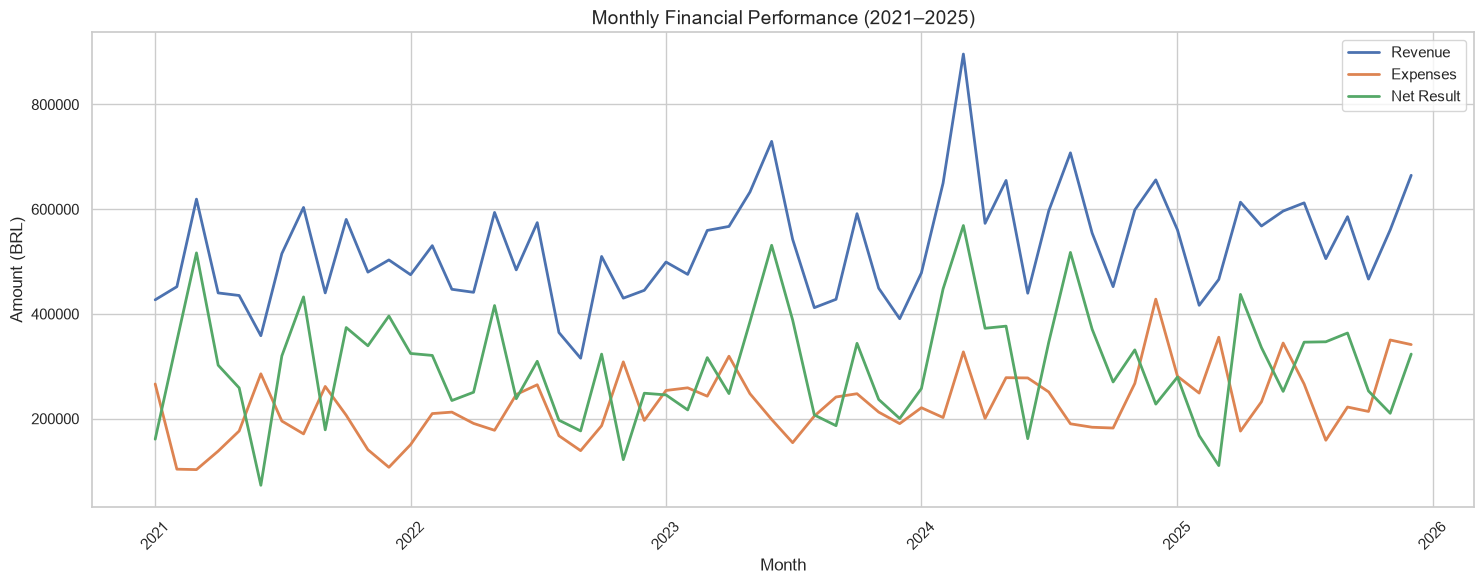

In [18]:
# Monthly financial performance visualization

plt.figure(figsize=(15, 6))

plt.plot(
    df['month'],
    df['revenue_brl'],
    label='Revenue',
    linewidth=2
)

plt.plot(
    df['month'],
    df['expenses_brl'],
    label='Expenses',
    linewidth=2
)

plt.plot(
    df['month'],
    df['net_result_brl'],
    label='Net Result',
    linewidth=2
)

plt.title('Monthly Financial Performance (2021–2025)', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Amount (BRL)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 3. Annual Financial Performance Analysis

This section compares the financial performance across the five-year period.

The analysis focuses on annual revenue, expenses, net results, transaction volumes, and net profit margins to identify long-term trends and changes in financial performance.

In [19]:
# Annual financial performance analysis

annual_performance = (
    df.assign(year=df['month'].dt.year)
    .groupby('year')
    .agg(
        months_analyzed=('month', 'nunique'),
        total_revenue_brl=('revenue_brl', 'sum'),
        total_expenses_brl=('expenses_brl', 'sum'),
        total_net_result_brl=('net_result_brl', 'sum'),
        total_transactions=('transaction_count', 'sum')
    )
    .reset_index()
)

# Calculate annual net profit margin
annual_performance['net_margin_pct'] = (
    annual_performance['total_net_result_brl'] /
    annual_performance['total_revenue_brl']
) * 100

# Display annual results
annual_performance

,year,months_analyzed,total_revenue_brl,total_expenses_brl,total_net_result_brl,total_transactions,net_margin_pct
0,2021,12,"5,854,141.23","2,154,514.66","3,699,626.57",974,63.20
1,2022,12,"5,610,774.71","2,449,720.59","3,161,054.12",977,56.34
2,2023,12,"6,277,347.92","2,771,897.56","3,505,450.36",993,55.84
3,2024,12,"7,257,548.59","3,009,184.90","4,248,363.69",1007,58.54
4,2025,12,"6,615,627.09","3,190,449.49","3,425,177.60",985,51.77


In [20]:
# Identify the best and worst financial years

best_year = annual_performance.loc[
    annual_performance['total_net_result_brl'].idxmax()
]

worst_year = annual_performance.loc[
    annual_performance['total_net_result_brl'].idxmin()
]

print("BEST FINANCIAL YEAR")
print("-" * 40)
print(f"Year: {int(best_year['year'])}")
print(f"Revenue: R$ {best_year['total_revenue_brl']:,.2f}")
print(f"Net Result: R$ {best_year['total_net_result_brl']:,.2f}")
print(f"Net Margin: {best_year['net_margin_pct']:.2f}%")

print("\nWORST FINANCIAL YEAR")
print("-" * 40)
print(f"Year: {int(worst_year['year'])}")
print(f"Revenue: R$ {worst_year['total_revenue_brl']:,.2f}")
print(f"Net Result: R$ {worst_year['total_net_result_brl']:,.2f}")
print(f"Net Margin: {worst_year['net_margin_pct']:.2f}%")

BEST FINANCIAL YEAR
----------------------------------------
Year: 2024
Revenue: R$ 7,257,548.59
Net Result: R$ 4,248,363.69
Net Margin: 58.54%

WORST FINANCIAL YEAR
----------------------------------------
Year: 2022
Revenue: R$ 5,610,774.71
Net Result: R$ 3,161,054.12
Net Margin: 56.34%


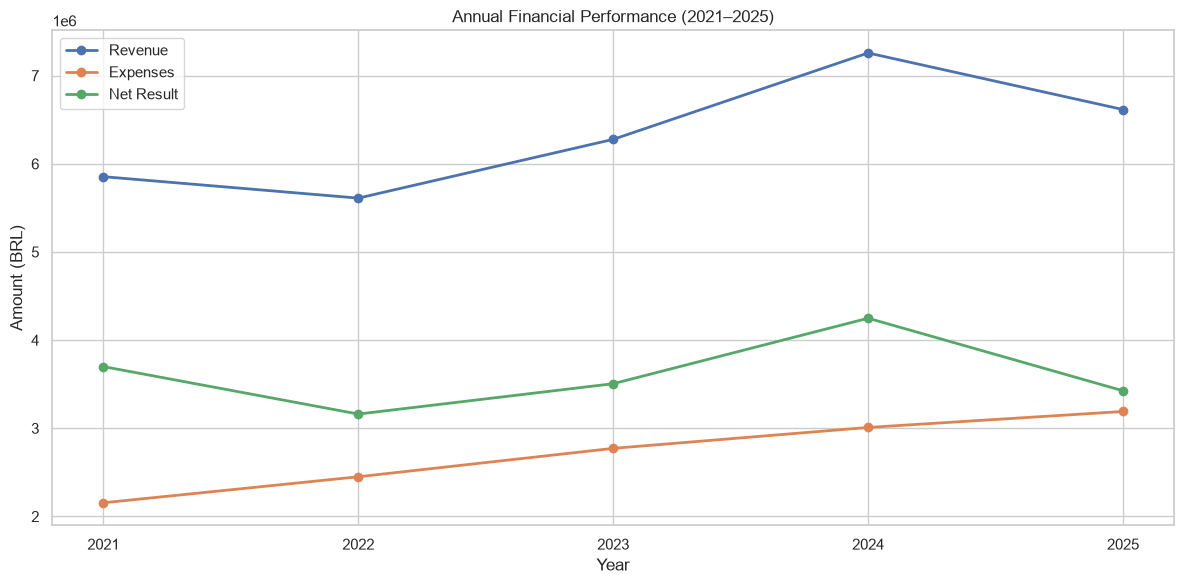

In [21]:
# Annual financial performance visualization

plt.figure(figsize=(12, 6))

plt.plot(
    annual_performance['year'],
    annual_performance['total_revenue_brl'],
    marker='o',
    linewidth=2,
    label='Revenue'
)

plt.plot(
    annual_performance['year'],
    annual_performance['total_expenses_brl'],
    marker='o',
    linewidth=2,
    label='Expenses'
)

plt.plot(
    annual_performance['year'],
    annual_performance['total_net_result_brl'],
    marker='o',
    linewidth=2,
    label='Net Result'
)

plt.title('Annual Financial Performance (2021–2025)')
plt.xlabel('Year')
plt.ylabel('Amount (BRL)')
plt.xticks(annual_performance['year'])
plt.legend()
plt.tight_layout()

plt.show()